In [1]:
# notebook 09, AdaBoost: who breaks, asked by a committee of single questions. Kernel: Python (yjmob)
# The same people, features and label as the trees of notebook 04 (34 features from days 0-44; broke = the habit model stopped describing
# the person in the emergency). Stumps are fitted one after another, each on the people the earlier ones got wrong; a from-scratch copy
# follows those row weights round by round. It reads only tables saved by notebook 04 and runs in a few minutes on 8 CPU cores
import sys, json, time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
ROOT, REPO = Path("/projects/ancz7294/yjmob"), Path("/projects/ancz7294/agent-reliability-under-disruption")
PROC = ROOT / "data/processed"
FIG, SAMPLE, LOGS = REPO / "site/src/assets/figures", REPO / "data/samples", REPO / "logs"
SEED = 20260917
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "text.color": "#0b0b0b", "axes.labelcolor": "#52514e", "xtick.color": "#898781", "ytick.color": "#898781",
    "font.family": "sans-serif", "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight"})
def save(fig, name): fig.savefig(FIG / f"{name}.png"); plt.show(); plt.close(fig)

def table_png(df, name, title, width=11, mono=(), widths=None):
    fig, ax = plt.subplots(figsize=(width, 0.3 * (len(df) + 1))); fig.subplots_adjust(0, 0, 1, 1); ax.axis("off"); ax.grid(False)
    w = np.asarray(widths if widths is not None else [1.0] * df.shape[1], float); w = w / w.sum()
    tb = ax.table(cellText=df.astype(str).values, colLabels=list(df.columns), cellLoc="left", colLoc="left", colWidths=list(w), bbox=[0, 0, 1, 1])
    tb.auto_set_font_size(False); tb.set_fontsize(8.5)
    for (r, c), cell in tb.get_celld().items():
        cell.set_edgecolor("#e1e0d9"); cell.PAD = 0.08 / (w[c] * width)
        if r == 0: cell.set_facecolor("#e8f0fb"); cell.set_text_props(weight="bold")
        elif df.columns[c] in mono: cell.set_text_props(family="monospace")
    ax.set_title(title, loc="left", fontweight="bold", fontsize=11, pad=8); save(fig, name)

ORDER = ["far roamers", "mid-range movers", "regular commuters", "local regulars", "weekend movers", "homebodies"]
wb = pd.read_parquet(PROC / "who_breaks_table.parquet")
trees = pd.read_parquet(PROC / "tree_test_scores.parquet")                   # the three Part 3 trees on the test people
fm = pd.read_parquet(PROC / "fm_tabpfn35_test_scores.parquet")
X = wb.drop(columns=["broke", "split", "kind"]); y = wb.broke.astype(int)
is_tr, is_te = (wb.split == "dev").to_numpy(), (wb.split == "eval").to_numpy()
Xtr, Xte, ytr, yte = X[is_tr], X[is_te], y[is_tr], y[is_te]
print(f"{X.shape[1]} features | training {len(Xtr):,} people ({ytr.mean():.1%} broke) | test {len(Xte):,} ({yte.mean():.1%} broke) | overlap {len(set(Xtr.index) & set(Xte.index))}")
print("test people in the same order as the saved tree scores:", bool((trees.index == Xte.index).all()), "| TabPFN scores:", fm.columns.tolist()[:4], len(fm))

34 features | training 16,769 people (19.2% broke) | test 7,135 (18.9% broke) | overlap 0
test people in the same order as the saved tree scores: True | TabPFN scores: ['y', 'p'] 7135


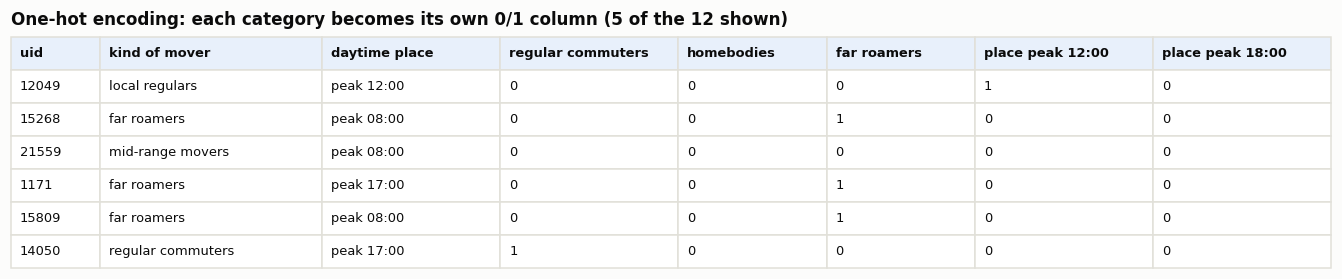

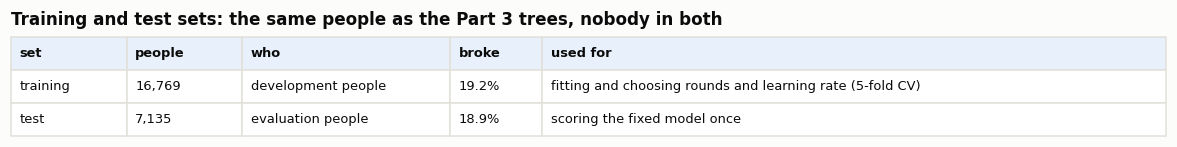

In [2]:
# data prep: scikit-learn's AdaBoost needs numbers, so the two categories (kind of mover, rhythm of the daytime place) became 0/1 columns
# in notebook 04; the table below shows that step for six training people. Then the training and test sets
ONEHOT = [c for c in X.columns if c.startswith("kind: ") or c.startswith("daytime place: ")]
show = wb[is_tr].sample(6, random_state=SEED)
place = show[[c for c in ONEHOT if c.startswith("daytime place: ")]].idxmax(axis=1).str.replace("daytime place: ", "")
t21 = pd.DataFrame({"uid": show.index, "kind of mover": show.kind.to_numpy(), "daytime place": place.to_numpy()})
for c in ["kind: regular commuters", "kind: homebodies", "kind: far roamers", "daytime place: peak 12:00", "daytime place: peak 18:00"]:
    t21[c.replace("kind: ", "").replace("daytime place: ", "place ")] = show[c].to_numpy()
table_png(t21, "t21_onehot", "One-hot encoding: each category becomes its own 0/1 column (5 of the 12 shown)", 12,
          widths=[0.06, 0.15, 0.12, 0.12, 0.1, 0.1, 0.12, 0.12])
t22 = pd.DataFrame({"set": ["training", "test"], "people": [f"{len(Xtr):,}", f"{len(Xte):,}"], "who": ["development people", "evaluation people"],
                    "broke": [f"{ytr.mean():.1%}", f"{yte.mean():.1%}"], "used for": ["fitting and choosing rounds and learning rate (5-fold CV)", "scoring the fixed model once"]})
table_png(t22, "t22_adaboost_split", "Training and test sets: the same people as the Part 3 trees, nobody in both", 10.5, widths=[0.1, 0.1, 0.18, 0.08, 0.54])

25 fits of 1500 rounds in 161 s
  lr  rounds    AUC  accuracy  balanced
0.05    1500 0.6438    0.6510    0.6039
0.10    1500 0.6473    0.6510    0.6088
0.25    1500 0.6492    0.6493    0.6117
0.50    1500 0.6496    0.6484    0.6121
1.00    1500 0.6468    0.6346    0.6053
chosen: learning rate 0.5, 1500 rounds, cross-validated AUC 0.6496, accuracy 0.6484, balanced 0.6121


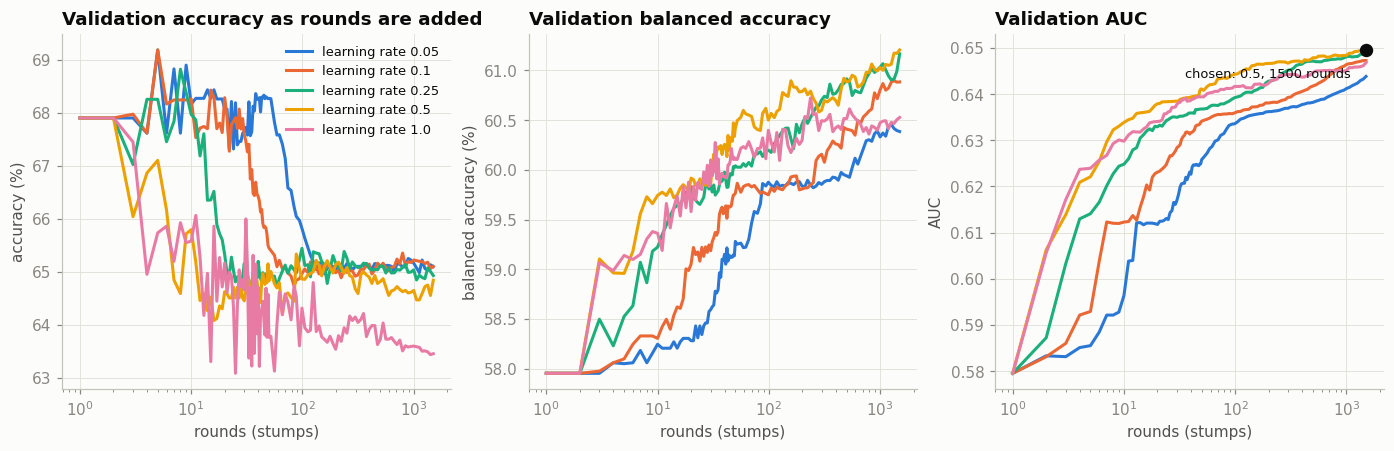

In [3]:
# rounds and learning rate chosen by 5-fold cross-validation on the training people. 'broke' is one in five, so each fit starts from
# balanced row weights (the same idea as the class weights of the trees); every round's score comes from staged predictions of one fit
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import accuracy_score, balanced_accuracy_score, roc_auc_score, confusion_matrix
from joblib import Parallel, delayed
ROUNDS, RATES = 1500, [0.05, 0.1, 0.25, 0.5, 1.0]
stump = lambda: DecisionTreeClassifier(max_depth=1, random_state=SEED)
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
folds = list(cv.split(Xtr, ytr))
def fold_curve(lr, f):
    a, b = folds[f]
    m = AdaBoostClassifier(stump(), n_estimators=ROUNDS, learning_rate=lr, random_state=SEED)
    m.fit(Xtr.iloc[a], ytr.iloc[a], sample_weight=compute_sample_weight("balanced", ytr.iloc[a]))
    yb = ytr.iloc[b].to_numpy(); out = []
    for r, d in enumerate(m.staged_decision_function(Xtr.iloc[b]), 1):
        if r in STEPS: out.append((lr, f, r, roc_auc_score(yb, d), accuracy_score(yb, d > 0), balanced_accuracy_score(yb, d > 0)))
    return out
STEPS = set(np.unique(np.r_[np.arange(1, 50), np.geomspace(50, ROUNDS, 60).astype(int)]))
t0 = time.time()
cur = pd.DataFrame([r for o in Parallel(n_jobs=8)(delayed(fold_curve)(lr, f) for lr in RATES for f in range(5)) for r in o],
                   columns=["lr", "fold", "rounds", "AUC", "accuracy", "balanced"])
print(f"{len(RATES) * 5} fits of {ROUNDS} rounds in {time.time() - t0:.0f} s")
mc = cur.groupby(["lr", "rounds"])[["AUC", "accuracy", "balanced"]].mean().reset_index()
bst = mc.loc[mc.AUC.idxmax()]; LR, NR = float(bst.lr), int(bst.rounds)
print(mc.loc[mc.groupby("lr").AUC.idxmax()].round(4).to_string(index=False))
print(f"chosen: learning rate {LR}, {NR} rounds, cross-validated AUC {bst.AUC:.4f}, accuracy {bst.accuracy:.4f}, balanced {bst.balanced:.4f}")
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.2), sharex=True)
for j, lr in enumerate(RATES):
    g_ = mc[mc.lr == lr]
    for ax, v in zip(axes, ["accuracy", "balanced", "AUC"]): ax.plot(g_.rounds, g_[v] * (100 if v != "AUC" else 1), color=C[j], lw=2, label=f"learning rate {lr}")
for ax, v, t in zip(axes, ["accuracy", "balanced accuracy", "AUC"], ["Validation accuracy as rounds are added", "Validation balanced accuracy", "Validation AUC"]):
    ax.set(xscale="log", xlabel="rounds (stumps)", ylabel=v + (" (%)" if v != "AUC" else ""), title=t)
axes[2].scatter([NR], [bst.AUC], s=60, color="#0b0b0b", zorder=5); axes[2].annotate(f"chosen: {LR}, {NR} rounds", (NR, bst.AUC), textcoords="offset points", xytext=(-10, -18), ha="right", fontsize=8.5)
axes[0].legend(frameon=False, fontsize=8.5)
save(fig, "f59_adaboost_rounds")

                           accuracy balanced accuracy       AUC AdaBoost minus this, AUC      95% interval
AdaBoost, stumps            0.64527          0.601497  0.645258                      NaN                  
tree 1, depth 2            0.738472          0.571978  0.599628                  0.04563  +0.036 to +0.056
tree 2, tuned              0.583041           0.59394  0.629043                 0.016216  +0.005 to +0.028
tree 3, grown fully        0.707919           0.52635   0.52635                 0.118908  +0.101 to +0.138
TabPFN-3.5 (Part 3 check)  0.638963          0.620989   0.66451                -0.019251  -0.027 to -0.011
always 'held': accuracy 0.811


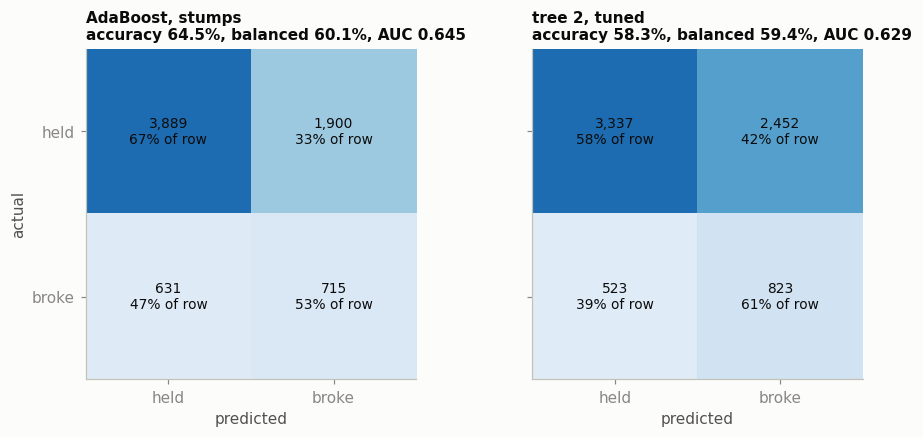

confusion (tn, fp, fn, tp): {'AdaBoost, stumps': [3889, 1900, 631, 715], 'tree 2, tuned': [3337, 2452, 523, 823]}


In [4]:
# the chosen committee on all training people, scored once on the test people against the Part 3 trees (same people, same features).
# AUC differences get 95% intervals from 1,000 bootstrap samples of test people, paired (the same people for both models)
ada = AdaBoostClassifier(stump(), n_estimators=NR, learning_rate=LR, random_state=SEED).fit(Xtr, ytr, sample_weight=compute_sample_weight("balanced", ytr))
s_ada = ada.decision_function(Xte)
assert (fm.y.to_numpy() == yte.to_numpy()).all()
SC = {"AdaBoost, stumps": s_ada, "tree 1, depth 2": trees["tree 1, depth 2"].to_numpy(), "tree 2, tuned": trees["tree 2, tuned"].to_numpy(),
      "tree 3, grown fully": trees["tree 3, grown fully"].to_numpy(), "TabPFN-3.5 (Part 3 check)": fm.p.to_numpy()}
THR = {"AdaBoost, stumps": 0.0, "TabPFN-3.5 (Part 3 check)": ytr.mean()}                  # the trees decide at 0.5 with balanced classes
yv = yte.to_numpy(); rng = np.random.default_rng(SEED); bi = [rng.integers(0, len(yv), len(yv)) for _ in range(1000)]
rows_t = {}
for nm, s in SC.items():
    pr = s > THR.get(nm, 0.5)
    d = np.array([roc_auc_score(yv[b], s_ada[b]) - roc_auc_score(yv[b], s[b]) for b in bi]) if nm != "AdaBoost, stumps" else None
    rows_t[nm] = {"accuracy": accuracy_score(yv, pr), "balanced accuracy": balanced_accuracy_score(yv, pr), "AUC": roc_auc_score(yv, s),
                  "AdaBoost minus this, AUC": np.nan if d is None else roc_auc_score(yv, s_ada) - roc_auc_score(yv, s),
                  "95% interval": "" if d is None else f"{np.percentile(d, 2.5):+.3f} to {np.percentile(d, 97.5):+.3f}"}
ttab = pd.DataFrame(rows_t).T; print(ttab.to_string()); print(f"always 'held': accuracy {1 - yv.mean():.3f}")
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.9))
for ax, nm in zip(axes, ["AdaBoost, stumps", "tree 2, tuned"]):
    cm = confusion_matrix(yv, SC[nm] > THR.get(nm, 0.5))
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=cm.max() * 1.3); ax.grid(False)
    for (r, c_), v in np.ndenumerate(cm): ax.text(c_, r, f"{v:,}\n{v / cm[r].sum():.0%} of row", ha="center", va="center", fontsize=9)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["held", "broke"]); ax.set_yticks([0, 1]); ax.set_yticklabels(["held", "broke"]); ax.set_xlabel("predicted")
    ax.set_title(f"{nm}\naccuracy {rows_t[nm]['accuracy']:.1%}, balanced {rows_t[nm]['balanced accuracy']:.1%}, AUC {rows_t[nm]['AUC']:.3f}", fontsize=10)
axes[0].set_ylabel("actual"); axes[1].set_yticklabels([])
save(fig, "f60_adaboost_confusion")
print("confusion (tn, fp, fn, tp):", {nm: confusion_matrix(yv, SC[nm] > THR.get(nm, 0.5)).ravel().tolist() for nm in ["AdaBoost, stumps", "tree 2, tuned"]})

 round       feature  threshold    broke if  alpha  weighted error
     1    regularity      0.725       above  0.167           0.417
     2    commute_km      0.604       above  0.119           0.441
     3    regularity      0.611       above  0.110           0.445
     4  moving_share      0.752 at or below  0.068           0.466
     5    commute_km      1.059       above  0.076           0.462
     6       step_km      0.792 at or below  0.052           0.474
     7    home_share      0.060       above  0.057           0.471
     8 cells_per_day     10.606 at or below  0.024           0.488
     9    regularity      0.837       above  0.056           0.472
    10   night_share      0.146       above  0.040           0.480
    11 cells_per_day     10.606 at or below  0.039           0.481
    12 cells_per_day     12.770 at or below  0.011           0.495
refitted tuned tree, test AUC: 0.629 (Part 3: 0.629)
                      AdaBoost, share of the vote  tuned tree, importance
en

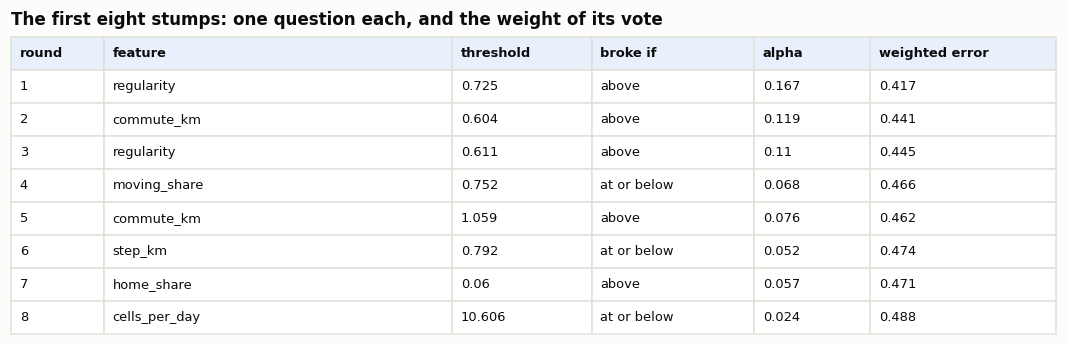

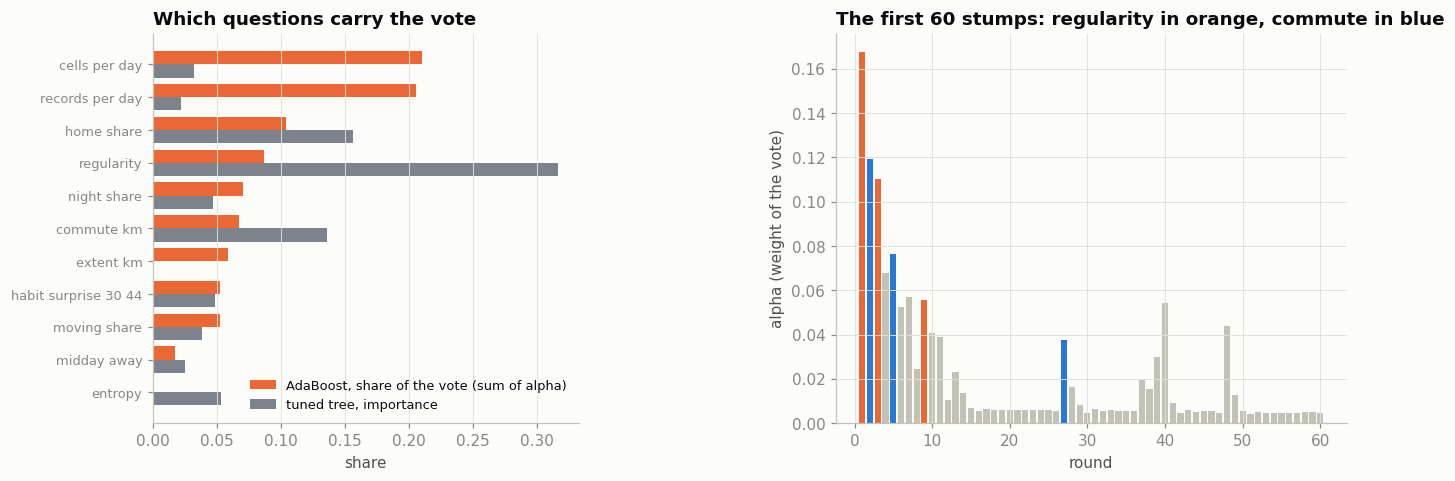

In [5]:
# what the committee asks: each stump is one question about one feature; alpha is how loud its vote is. The first questions, and how the
# whole vote is shared between features, beside the importance of the tuned Part 3 tree (refitted with its chosen settings)
names = np.asarray(X.columns)
st = pd.DataFrame({"round": np.arange(1, len(ada.estimators_) + 1), "feature": [names[e.tree_.feature[0]] for e in ada.estimators_],
                   "threshold": [e.tree_.threshold[0] for e in ada.estimators_],
                   "broke if": [("above" if e.tree_.value[2][0][1] / e.tree_.value[2][0].sum() > e.tree_.value[1][0][1] / e.tree_.value[1][0].sum() else "at or below") for e in ada.estimators_],
                   "alpha": ada.estimator_weights_[:len(ada.estimators_)], "weighted error": ada.estimator_errors_[:len(ada.estimators_)]})
print(st.head(12).round(3).to_string(index=False))
share = st.groupby("feature").alpha.sum().div(st.alpha.sum()).sort_values(ascending=False)
t2 = DecisionTreeClassifier(criterion="gini", max_depth=10, min_samples_leaf=200, class_weight="balanced", random_state=SEED).fit(Xtr, ytr)
print("refitted tuned tree, test AUC:", round(roc_auc_score(yv, t2.predict_proba(Xte)[:, 1]), 4), "(Part 3: 0.629)")
imp = pd.Series(t2.feature_importances_, index=names)
top = share.head(10).index.union(imp.sort_values(ascending=False).head(6).index)
cmpf = pd.DataFrame({"AdaBoost, share of the vote": share, "tuned tree, importance": imp}).fillna(0).loc[top].sort_values("AdaBoost, share of the vote")
print(cmpf.round(3).to_string()); print(f"features ever asked: {st.feature.nunique()} of {len(names)} | stumps on regularity: {(st.feature == 'regularity').sum()} of {len(st)}")
t23 = st.head(8).assign(threshold=lambda d: d.threshold.round(3), alpha=lambda d: d.alpha.round(3), **{"weighted error": lambda d: d["weighted error"].round(3)})
table_png(t23, "t23_first_stumps", "The first eight stumps: one question each, and the weight of its vote", 9.5, widths=[0.08, 0.3, 0.12, 0.14, 0.1, 0.16])
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1, 1.2], "wspace": 0.55})
ax = axes[0]; yy = np.arange(len(cmpf)); short = lambda f: f.replace("_", " ")
ax.barh(yy + 0.2, cmpf["AdaBoost, share of the vote"], 0.4, color=C[1], label="AdaBoost, share of the vote (sum of alpha)")
ax.barh(yy - 0.2, cmpf["tuned tree, importance"], 0.4, color="#7d838c", label="tuned tree, importance")
ax.set_yticks(yy); ax.set_yticklabels([short(f) for f in cmpf.index], fontsize=8.5); ax.yaxis.grid(False)
ax.set(xlabel="share", title="Which questions carry the vote"); ax.legend(frameon=False, fontsize=8.5, loc="lower right")
ax = axes[1]; n_ = 60
ax.bar(st["round"][:n_], st.alpha[:n_], color=[C[1] if f == "regularity" else (C[0] if f == "commute_km" else "#c3c2b7") for f in st.feature[:n_]], width=0.8)
ax.set(xlabel="round", ylabel="alpha (weight of the vote)", title="The first 60 stumps: regularity in orange, commute in blue")
save(fig, "f61_stumps_and_votes")

1500 rounds in 50 s | same test ranking as scikit-learn: AUC 0.6453 against 0.6453, correlation 1.000000
share of all weight by group, start and after rounds:
                       0      1      2      5      10     25     50     100    250    500    1000   1500
group                                                                                                   
broke, 2nd            0.076  0.084  0.082  0.088  0.091  0.089  0.089  0.089  0.091  0.091  0.091  0.092
broke, 3rd            0.081  0.089  0.087  0.093  0.095  0.093  0.093  0.093  0.095  0.095  0.095  0.095
broke, 4th            0.111  0.114  0.111  0.106  0.107  0.105  0.104  0.104  0.104  0.104  0.104  0.105
broke, least regular  0.076  0.083  0.081  0.087  0.090  0.088  0.088  0.088  0.090  0.090  0.090  0.091
broke, most regular   0.155  0.144  0.140  0.132  0.127  0.124  0.123  0.122  0.119  0.119  0.119  0.119
held, 2nd             0.105  0.097  0.100  0.094  0.092  0.094  0.094  0.093  0.092  0.092  0.092  0.091
h

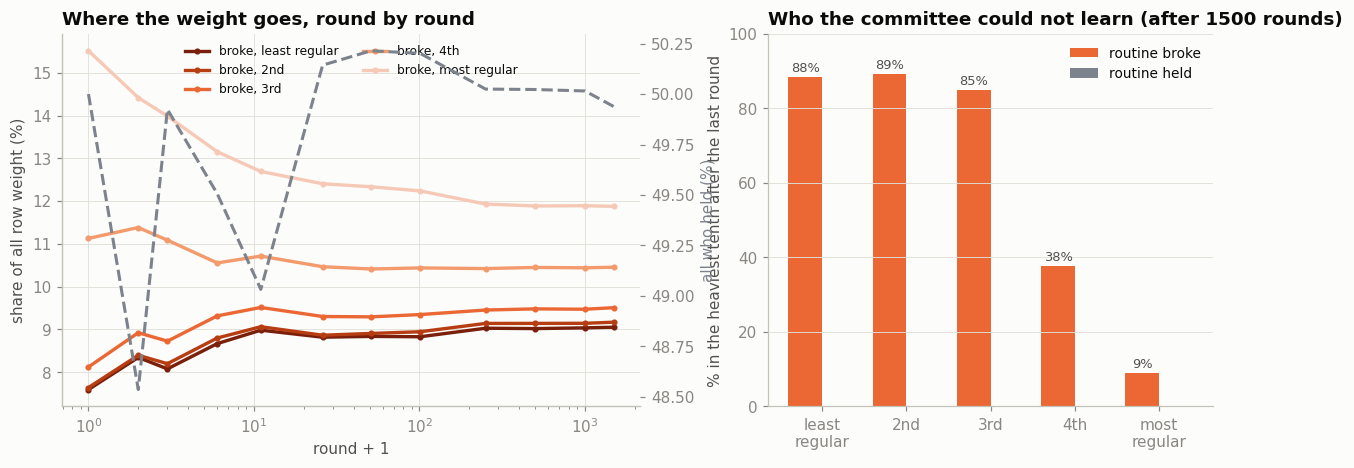

In [6]:
# who the committee keeps getting wrong. AdaBoost from scratch (the same algorithm as scikit-learn's, SAMME with two classes), so the row
# weights can be followed round by round: after each stump, the people it got wrong weigh exp(alpha) times more, then all are rescaled
def adaboost_weights(X_, y_, rounds, lr, w0):
    w = w0 / w0.sum(); keep = {}; stumps = []
    for r in range(1, rounds + 1):
        s = DecisionTreeClassifier(max_depth=1, random_state=SEED).fit(X_, y_, sample_weight=w)
        miss = s.predict(X_) != y_; err = w[miss].sum() / w.sum()
        if err <= 0 or err >= 0.5: break
        alpha = lr * np.log((1 - err) / err)
        w = w * np.exp(alpha * miss); w = w / w.sum(); stumps.append((s, alpha))
        if r in (1, 2, 5, 10, 25, 50, 100, 250, 500, 1000, rounds): keep[r] = w.copy()
    return keep, stumps
w0 = compute_sample_weight("balanced", ytr)
t0 = time.time(); keep, mine = adaboost_weights(Xtr.to_numpy(), ytr.to_numpy(), NR, LR, w0)
d_mine = sum(a * np.where(s.predict(Xte.to_numpy()) == 1, 1, -1) for s, a in mine)
print(f"{len(mine)} rounds in {time.time() - t0:.0f} s | same test ranking as scikit-learn: AUC {roc_auc_score(yv, d_mine):.4f} against {roc_auc_score(yv, s_ada):.4f}, "
      f"correlation {np.corrcoef(d_mine, s_ada)[0, 1]:.6f}")
P = pd.DataFrame({"broke": ytr.to_numpy(), "fifth": pd.qcut(Xtr.regularity, 5, labels=["least regular", "2nd", "3rd", "4th", "most regular"]).to_numpy(),
                  "kind": wb.kind[is_tr].to_numpy()}, index=Xtr.index)
P["group"] = np.where(P.broke == 1, "broke, ", "held, ") + P.fifth.astype(str)
traj = pd.DataFrame({r: pd.Series(w, index=Xtr.index).groupby(P.group).sum() for r, w in keep.items()}).T
start = pd.Series(w0 / w0.sum(), index=Xtr.index).groupby(P.group).sum()
print("share of all weight by group, start and after rounds:"); print(pd.concat([start.rename(0).to_frame().T, traj]).round(3).T.to_string())
wf = pd.Series(keep[max(keep)], index=Xtr.index); hard = wf >= wf.quantile(0.9)
print(f"the 10% heaviest people at the end hold {wf[hard].sum():.1%} of all weight; of them broke {P.broke[hard].mean():.1%} (all training people {P.broke.mean():.1%})")
print(pd.crosstab(P.fifth[hard], P.broke[hard], normalize="all").round(3).to_string())
print("heaviest 10%, by kind:", P.kind[hard].value_counts(normalize=True).reindex(ORDER).round(3).to_dict())
fifths = ["least regular", "2nd", "3rd", "4th", "most regular"]
inhard = (P[hard & (P.broke == 1)].fifth.value_counts() / P[P.broke == 1].fifth.value_counts()).reindex(fifths)
inhard_h = (P[hard & (P.broke == 0)].fifth.value_counts().reindex(fifths).fillna(0) / P[P.broke == 0].fifth.value_counts().reindex(fifths))
print("share of each fifth's broken routines in the heaviest tenth:", inhard.round(3).to_dict(), "| held:", inhard_h.round(3).to_dict())
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.4), gridspec_kw={"width_ratios": [1.3, 1], "wspace": 0.25})
ax = axes[0]; rr = np.array([0] + list(traj.index)) + 1
shades = ["#7a1f0a", "#b73d12", C[1], "#f39b6d", "#f6c9b6"]
for f_, c_ in zip(fifths, shades):
    v = [start[f"broke, {f_}"]] + list(traj[f"broke, {f_}"]); ax.plot(rr, np.array(v) * 100, color=c_, lw=2.2, marker="o", ms=3, label=f"broke, {f_}")
held = [start[[g for g in start.index if g.startswith("held")]].sum()] + list(traj[[g for g in traj.columns if g.startswith("held")]].sum(axis=1))
ax2 = ax.twinx(); ax2.plot(rr, np.array(held) * 100, color="#7d838c", lw=2, ls="--"); ax2.set_ylabel("all who held (%)", color="#7d838c"); ax2.grid(False)
ax.set(xscale="log", xlabel="round + 1", ylabel="share of all row weight (%)", title="Where the weight goes, round by round")
ax.legend(frameon=False, fontsize=8, ncol=2, loc="upper center")
ax = axes[1]; x = np.arange(5)
ax.bar(x - 0.2, inhard * 100, 0.4, color=C[1], label="routine broke"); ax.bar(x + 0.2, inhard_h * 100, 0.4, color="#7d838c", label="routine held")
for xi, v in zip(x, inhard): ax.text(xi - 0.2, v * 100 + 1.5, f"{v:.0%}", ha="center", fontsize=8.5, color="#52514e")
ax.set_xticks(x); ax.set_xticklabels(["least\nregular", "2nd", "3rd", "4th", "most\nregular"]); ax.xaxis.grid(False); ax.set_ylim(0, 100)
ax.set(ylabel="% in the heaviest tenth after the last round", title=f"Who the committee could not learn (after {NR} rounds)"); ax.legend(frameon=False, fontsize=9, loc="upper right")
save(fig, "f62_who_it_cannot_learn")

one day in (60 s): AUC 0.7158 against 0.6453 from ordinary days alone, gain +0.0706 (95% +0.059 to +0.083); accuracy 0.6985, balanced 0.6577
               ordinary days  one day in
least regular          0.589       0.678
2nd                    0.588       0.661
3rd                    0.651       0.683
4th                    0.605       0.711
most regular           0.580       0.704
checking the 20% highest-risk test people finds: {'ordinary days': {'all breaks': 0.334, 'least regular two fifths': 0.024}, 'one day in': {'all breaks': 0.432, 'least regular two fifths': 0.171}}
share of the vote on the day-60 inputs: {'day60_seen': 0.01, 'day60_vs_habit': 0.429, 'day60_away': 0.09}


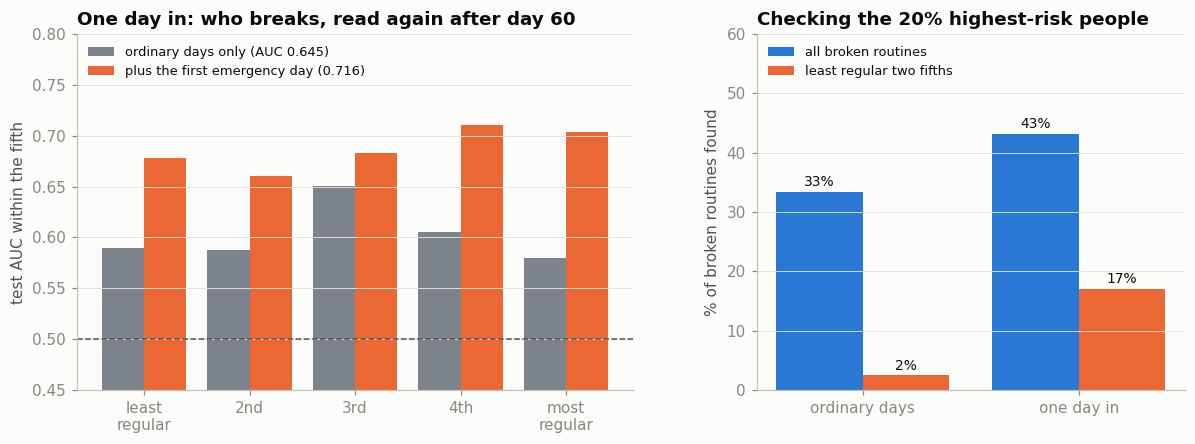

In [7]:
# one day in: the same committee given the first emergency day as well (whether the person was seen, the share of the day away from home,
# and how far that sat from their habit; from notebook 08's table). Day 60 is one of the fifteen days the label is built on, so this asks
# how much one day of the new situation adds to deciding whose agent to check first, not whether it can foresee a day it never saw
RP = pd.read_parquet(PROC / "regression_people.parquet").xs("emergency")
d60 = pd.read_parquet(PROC / "person_day_shares.parquet").query("d == 60").set_index("uid")
X1 = X.copy(); X1["day60_seen"] = d60.seen.reindex(X.index).fillna(0).to_numpy()
X1["day60_vs_habit"] = RP.fresh_1.reindex(X.index).fillna(0).to_numpy()
X1["day60_away"] = RP.fresh_share_1.reindex(X.index).fillna(RP.habit.reindex(X.index)).fillna(X.home_share.rsub(1)).to_numpy()
t0 = time.time()
ada1 = AdaBoostClassifier(stump(), n_estimators=NR, learning_rate=LR, random_state=SEED).fit(X1[is_tr], ytr, sample_weight=compute_sample_weight("balanced", ytr))
s1 = ada1.decision_function(X1[is_te])
d1 = np.array([roc_auc_score(yv[b], s1[b]) - roc_auc_score(yv[b], s_ada[b]) for b in bi])
one_day = {"AUC": roc_auc_score(yv, s1), "gain": roc_auc_score(yv, s1) - roc_auc_score(yv, s_ada), "lo": np.percentile(d1, 2.5), "hi": np.percentile(d1, 97.5),
           "accuracy": accuracy_score(yv, s1 > 0), "balanced": balanced_accuracy_score(yv, s1 > 0)}
print(f"one day in ({time.time() - t0:.0f} s): AUC {one_day['AUC']:.4f} against {roc_auc_score(yv, s_ada):.4f} from ordinary days alone, gain {one_day['gain']:+.4f} "
      f"(95% {one_day['lo']:+.3f} to {one_day['hi']:+.3f}); accuracy {one_day['accuracy']:.4f}, balanced {one_day['balanced']:.4f}")
fifth_te = pd.qcut(Xte.regularity, 5, labels=fifths)
auc_f = pd.DataFrame({nm: {f_: roc_auc_score(yv[(fifth_te == f_).to_numpy()], s[(fifth_te == f_).to_numpy()]) for f_ in fifths} for nm, s in [("ordinary days", s_ada), ("one day in", s1)]})
print(auc_f.round(3).to_string())
low2 = fifth_te.isin(fifths[:2]).to_numpy(); find = {}
for nm, s in [("ordinary days", s_ada), ("one day in", s1)]:
    k_ = np.zeros(len(s), bool); k_[np.argsort(-s)[: int(0.2 * len(s))]] = True
    find[nm] = {"all breaks": yv[k_].sum() / yv.sum(), "least regular two fifths": yv[k_ & low2].sum() / yv[low2].sum()}
print("checking the 20% highest-risk test people finds:", pd.DataFrame(find).round(3).to_dict())
sh1 = pd.Series(ada1.estimator_weights_, index=[X1.columns[e.tree_.feature[0]] for e in ada1.estimators_]).groupby(level=0).sum(); sh1 = sh1 / sh1.sum()
print("share of the vote on the day-60 inputs:", sh1.reindex(["day60_seen", "day60_vs_habit", "day60_away"]).round(3).to_dict())
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.3, 1], "wspace": 0.25})
ax = axes[0]; x = np.arange(5)
ax.bar(x - 0.2, auc_f["ordinary days"], 0.4, color="#7d838c", label=f"ordinary days only (AUC {roc_auc_score(yv, s_ada):.3f})")
ax.bar(x + 0.2, auc_f["one day in"], 0.4, color=C[1], label=f"plus the first emergency day ({one_day['AUC']:.3f})")
ax.axhline(0.5, color="#52514e", lw=1, ls="--"); ax.set_ylim(0.45, 0.8); ax.set_xticks(x); ax.set_xticklabels(["least\nregular", "2nd", "3rd", "4th", "most\nregular"]); ax.xaxis.grid(False)
ax.set(ylabel="test AUC within the fifth", title="One day in: who breaks, read again after day 60"); ax.legend(frameon=False, fontsize=8.5, loc="upper left")
ax = axes[1]; fd = pd.DataFrame(find).T * 100
ax.bar(np.arange(2) - 0.2, fd["all breaks"], 0.4, color=C[0], label="all broken routines"); ax.bar(np.arange(2) + 0.2, fd["least regular two fifths"], 0.4, color=C[1], label="least regular two fifths")
for i_, (a_, b_) in enumerate(fd.values): ax.text(i_ - 0.2, a_ + 1, f"{a_:.0f}%", ha="center", fontsize=9); ax.text(i_ + 0.2, b_ + 1, f"{b_:.0f}%", ha="center", fontsize=9)
ax.set_xticks([0, 1]); ax.set_xticklabels(list(fd.index)); ax.xaxis.grid(False); ax.set_ylim(0, 60)
ax.set(ylabel="% of broken routines found", title="Checking the 20% highest-risk people"); ax.legend(frameon=False, fontsize=8.5, loc="upper left")
save(fig, "f63_one_day_in")

In [8]:
# outputs: every number of this notebook in one log (the people and features are the published who_breaks_sample.csv of Part 3)
log = {"people": {"train": len(Xtr), "test": len(Xte), "features": X.shape[1]}, "chosen": {"learning_rate": LR, "rounds": NR, "cv_auc": round(float(bst.AUC), 4),
       "cv_accuracy": round(float(bst.accuracy), 4), "cv_balanced": round(float(bst.balanced), 4)},
       "cv_best_per_rate": mc.loc[mc.groupby("lr").AUC.idxmax()].round(4).to_dict(orient="records"),
       "cv_auc_by_rounds": mc.pivot(index="rounds", columns="lr", values="AUC").round(4).loc[[1, 10, 49, 50]].to_dict(),
       "test": ttab.to_dict(), "confusion_tn_fp_fn_tp": {nm: confusion_matrix(yv, SC[nm] > THR.get(nm, 0.5)).ravel().tolist() for nm in ["AdaBoost, stumps", "tree 2, tuned"]},
       "first_stumps": st.head(12).round(4).to_dict(orient="records"), "vote_share": share.round(4).to_dict(), "tree_importance": imp.round(4).to_dict(),
       "weight_share_by_group": pd.concat([start.rename(0).to_frame().T, traj]).round(4).T.to_dict(),
       "heaviest_tenth": {"weight": round(float(wf[hard].sum()), 4), "broke": round(float(P.broke[hard].mean()), 4),
                          "share_of_each_fifths_breaks": inhard.round(4).to_dict(), "by_kind": P.kind[hard].value_counts(normalize=True).round(4).to_dict()},
       "one_day_in": {k: round(float(v), 4) for k, v in one_day.items()}, "one_day_in_auc_by_fifth": auc_f.round(4).to_dict(),
       "one_day_in_top20": pd.DataFrame(find).round(4).to_dict(), "one_day_in_vote_share": sh1.round(4).to_dict()}
(LOGS / "part4_adaboost_log.json").write_text(json.dumps(log, indent=2, default=str))
print(json.dumps(log["chosen"]), json.dumps(log["one_day_in"]))
print(sorted(p.name for p in FIG.glob("f59*.png")) + sorted(p.name for p in FIG.glob("f6*.png")) + sorted(p.name for p in FIG.glob("t2[1-9]_*.png")))

{"learning_rate": 0.5, "rounds": 1500, "cv_auc": 0.6496, "cv_accuracy": 0.6484, "cv_balanced": 0.6121} {"AUC": 0.7158, "gain": 0.0706, "lo": 0.0586, "hi": 0.0826, "accuracy": 0.6985, "balanced": 0.6577}
['f59_adaboost_rounds.png', 'f60_adaboost_confusion.png', 'f61_stumps_and_votes.png', 'f62_who_it_cannot_learn.png', 'f63_one_day_in.png', 't21_onehot.png', 't22_adaboost_split.png', 't23_first_stumps.png']
